In [10]:
import os

file_path = "data/open-meteo-26.82N80.93E127m.csv"

print("File exists:", os.path.exists(file_path))

File exists: True


In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from io import StringIO
from pathlib import Path

# Step 1: CSV file ka path
file_path = Path("data/open-meteo-26.82N80.93E127m.csv")

# Step 2: Check file exists
if not file_path.exists():
    raise FileNotFoundError(
        f"File nahi mili: {file_path.resolve()}"
    )

# Step 3: Read file
with open(file_path, "r", encoding="utf-8-sig") as f:
    lines = f.readlines()

# Step 4: Find table headers
header_lines = [
    i for i, line in enumerate(lines)
    if line.strip().startswith("time,")
]

print("Header line numbers:", header_lines)

if len(header_lines) < 2:
    print("CSV ki starting lines:")
    print("".join(lines[:15]))
    raise ValueError("Hourly aur daily headers nahi mile.")

# Step 5: Separate hourly and daily data
hourly_text = "".join(lines[header_lines[0]:header_lines[1]])
daily_text = "".join(lines[header_lines[1]:])

hourly = pd.read_csv(StringIO(hourly_text))
daily = pd.read_csv(StringIO(daily_text))

# Step 6: Display results
print("Hourly shape:", hourly.shape)
print("Daily shape:", daily.shape)

print("\nHourly columns:")
print(hourly.columns.tolist())

print("\nDaily columns:")
print(daily.columns.tolist())

display(hourly.head())
display(daily.head())

Header line numbers: [3, 44573]
Hourly shape: (44568, 4)
Daily shape: (1857, 6)

Hourly columns:
['time', 'temperature_2m (°C)', 'weather_code (wmo code)', 'relative_humidity_2m (%)']

Daily columns:
['time', 'temperature_2m_mean (°C)', 'temperature_2m_max (°C)', 'temperature_2m_min (°C)', 'precipitation_sum (mm)', 'wind_speed_10m_max (km/h)']


,time,temperature_2m (°C),weather_code (wmo code),relative_humidity_2m (%)
0,2020-12-01T00:00,13.4,0,83
1,2020-12-01T01:00,13.4,0,83
2,2020-12-01T02:00,12.2,0,88
3,2020-12-01T03:00,11.6,0,90
4,2020-12-01T04:00,11.1,0,91


,time,temperature_2m_mean (°C),temperature_2m_max (°C),temperature_2m_min (°C),precipitation_sum (mm),wind_speed_10m_max (km/h)
0,2020-12-01,17.6,25.6,10.8,0.0,9.2
1,2020-12-02,18.0,25.6,12.2,0.0,11.8
2,2020-12-03,18.4,26.3,12.0,0.0,9.2
3,2020-12-04,18.6,25.9,13.0,0.0,9.0
4,2020-12-05,18.6,26.4,12.3,0.0,8.4


 Data Understanding

In [14]:
print("DAILY DATASET INFO")
daily.info()

print("\nMissing values in daily data:")
display(daily.isna().sum().to_frame("missing_values"))

print("\nDescriptive statistics:")
display(daily.describe().T)

print("\nDate range:")
daily["time"] = pd.to_datetime(daily["time"], errors="coerce")
print("Start:", daily["time"].min())
print("End:  ", daily["time"].max())
print("Number of rows:", len(daily))
print("Duplicate rows:", daily.duplicated().sum())

DAILY DATASET INFO
<class 'pandas.DataFrame'>
RangeIndex: 1857 entries, 0 to 1856
Data columns (total 6 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   time                       1857 non-null   str    
 1   temperature_2m_mean (°C)   1857 non-null   float64
 2   temperature_2m_max (°C)    1857 non-null   float64
 3   temperature_2m_min (°C)    1857 non-null   float64
 4   precipitation_sum (mm)     1857 non-null   float64
 5   wind_speed_10m_max (km/h)  1857 non-null   float64
dtypes: float64(5), str(1)
memory usage: 105.3 KB

Missing values in daily data:


,missing_values
time,0
temperature_2m_mean (°C),0
temperature_2m_max (°C),0
temperature_2m_min (°C),0
precipitation_sum (mm),0
wind_speed_10m_max (km/h),0



Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
temperature_2m_mean (°C),1857.0,25.013570,6.568601,8.7,19.5,27.2,29.7,39.5
temperature_2m_max (°C),1857.0,30.814432,6.351174,16.0,26.2,31.6,34.7,46.4
temperature_2m_min (°C),1857.0,19.938826,6.941693,3.5,13.7,22.0,25.8,33.6
precipitation_sum (mm),1857.0,2.746634,7.761329,0.0,0.0,0.0,1.1,129.8
wind_speed_10m_max (km/h),1857.0,14.509047,5.641868,2.8,10.0,13.4,17.8,39.9



Date range:
Start: 2020-12-01 00:00:00
End:   2025-12-31 00:00:00
Number of rows: 1857
Duplicate rows: 0


In [15]:
daily = daily.copy()
daily["time"] = pd.to_datetime(daily["time"], errors="coerce")
daily = daily.dropna(subset=["time"]).sort_values("time")
daily = daily.drop_duplicates(subset=["time"]).reset_index(drop=True)

for col in daily.columns:
    if col != "time":
        daily[col] = pd.to_numeric(daily[col], errors="coerce")

print("Columns:", daily.columns.tolist())
print("\nMissing values after conversion:")
display(daily.isna().sum().to_frame("missing_values"))

display(daily.head())

Columns: ['time', 'temperature_2m_mean (°C)', 'temperature_2m_max (°C)', 'temperature_2m_min (°C)', 'precipitation_sum (mm)', 'wind_speed_10m_max (km/h)']

Missing values after conversion:


,missing_values
time,0
temperature_2m_mean (°C),0
temperature_2m_max (°C),0
temperature_2m_min (°C),0
precipitation_sum (mm),0
wind_speed_10m_max (km/h),0


,time,temperature_2m_mean (°C),temperature_2m_max (°C),temperature_2m_min (°C),precipitation_sum (mm),wind_speed_10m_max (km/h)
0,2020-12-01,17.6,25.6,10.8,0.0,9.2
1,2020-12-02,18.0,25.6,12.2,0.0,11.8
2,2020-12-03,18.4,26.3,12.0,0.0,9.2
3,2020-12-04,18.6,25.9,13.0,0.0,9.0
4,2020-12-05,18.6,26.4,12.3,0.0,8.4


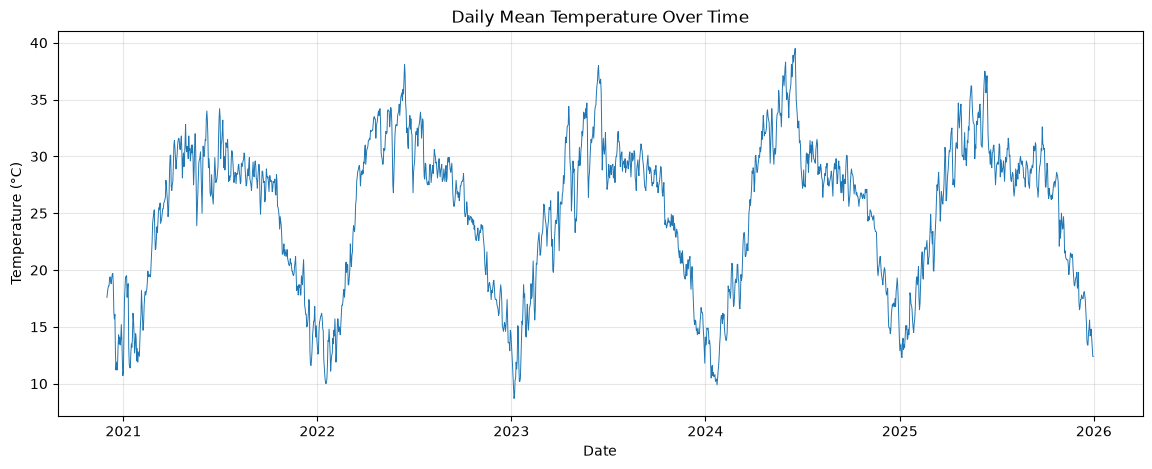

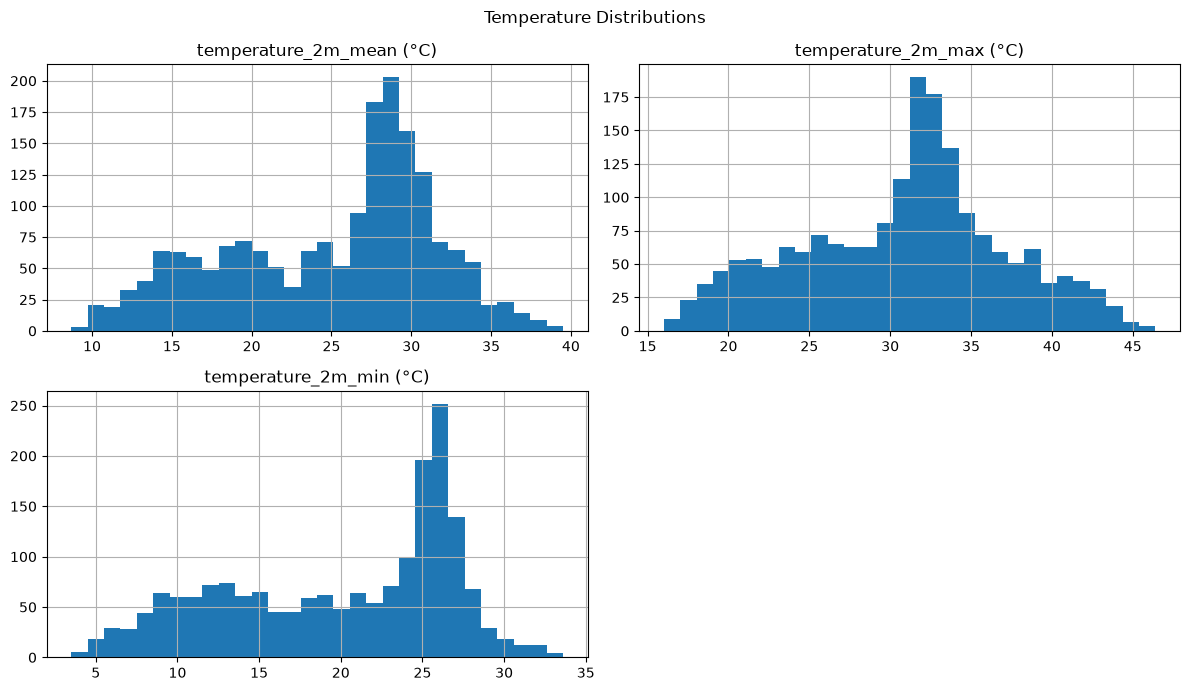

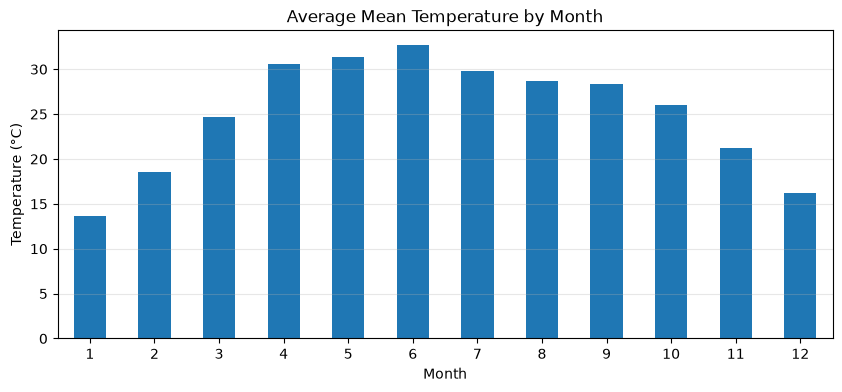

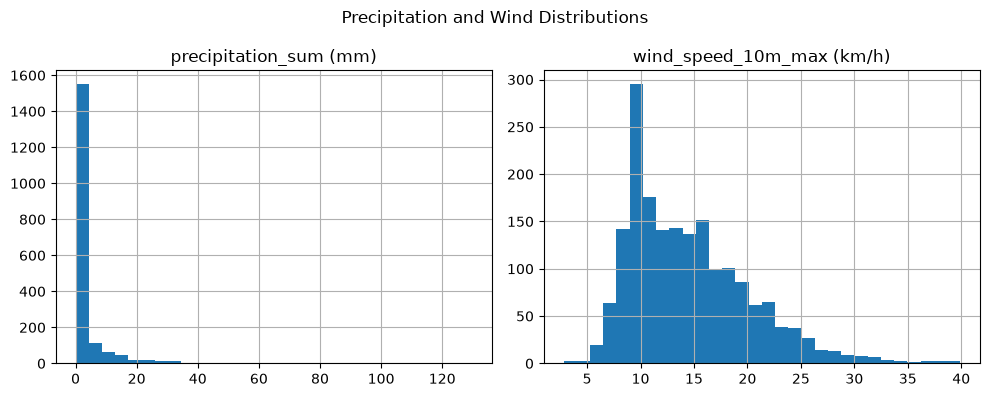

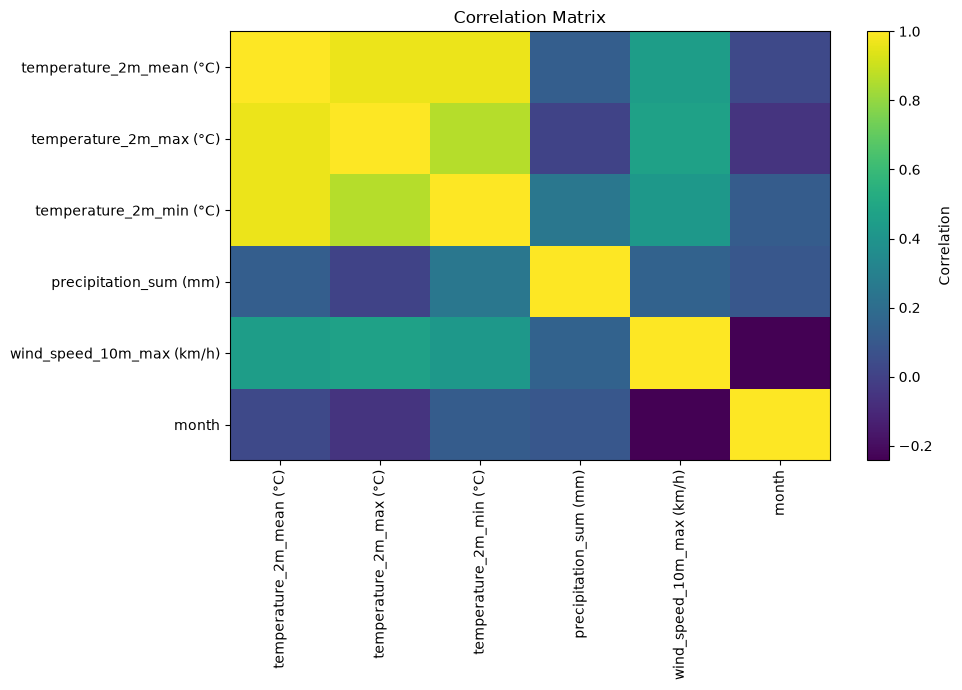

,temperature_2m_mean (°C),temperature_2m_max (°C),temperature_2m_min (°C),precipitation_sum (mm),wind_speed_10m_max (km/h),month
temperature_2m_mean (°C),1.00,0.96,0.96,0.13,0.45,0.03
temperature_2m_max (°C),0.96,1.00,0.86,0.01,0.47,-0.06
temperature_2m_min (°C),0.96,0.86,1.00,0.25,0.42,0.12
precipitation_sum (mm),0.13,0.01,0.25,1.00,0.15,0.09
wind_speed_10m_max (km/h),0.45,0.47,0.42,0.15,1.00,-0.24
month,0.03,-0.06,0.12,0.09,-0.24,1.00


In [16]:
# Daily mean temperature over time
mean_col = "temperature_2m_mean (°C)"
max_col = "temperature_2m_max (°C)"
min_col = "temperature_2m_min (°C)"

plt.figure(figsize=(14, 5))
plt.plot(daily["time"], daily[mean_col], linewidth=0.7)
plt.title("Daily Mean Temperature Over Time")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.grid(True, alpha=0.3)
plt.show()

# Temperature distributions
daily[[mean_col, max_col, min_col]].hist(figsize=(12, 7), bins=30)
plt.suptitle("Temperature Distributions")
plt.tight_layout()
plt.show()

# Monthly average temperature
daily["month"] = daily["time"].dt.month
monthly_avg = daily.groupby("month")[mean_col].mean()
plt.figure(figsize=(10, 4))
monthly_avg.plot(kind="bar")
plt.title("Average Mean Temperature by Month")
plt.xlabel("Month")
plt.ylabel("Temperature (°C)")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.show()

# Precipitation and wind distributions
other_cols = ["precipitation_sum (mm)", "wind_speed_10m_max (km/h)"]
available_other = [c for c in other_cols if c in daily.columns]
if available_other:
    daily[available_other].hist(figsize=(10, 4), bins=30)
    plt.suptitle("Precipitation and Wind Distributions")
    plt.tight_layout()
    plt.show()

# Correlation between numeric weather variables
numeric_daily = daily.select_dtypes(include="number")
plt.figure(figsize=(10, 7))
corr = numeric_daily.corr()
plt.imshow(corr, aspect="auto")
plt.colorbar(label="Correlation")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()
display(corr.round(2))

In [17]:
data = daily[["time", mean_col]].copy()
data = data.rename(columns={mean_col: "mean_temp"})

# Calendar features for the day whose temperature we want to predict
data["target_next_day"] = data["mean_temp"].shift(-1)
data["target_date"] = data["time"].shift(-1)
data["target_month"] = data["target_date"].dt.month
data["target_day_of_year"] = data["target_date"].dt.dayofyear

# Historical temperature features
data["temp_lag_0"] = data["mean_temp"]          # today's temperature
data["temp_lag_1"] = data["mean_temp"].shift(1)
data["temp_lag_3"] = data["mean_temp"].shift(3)
data["temp_lag_7"] = data["mean_temp"].shift(7)
data["rolling_mean_7"] = data["mean_temp"].shift(1).rolling(7).mean()

data = data.dropna().reset_index(drop=True)

feature_cols = [
    "target_month", "target_day_of_year",
    "temp_lag_0", "temp_lag_1", "temp_lag_3",
    "temp_lag_7", "rolling_mean_7"
]
X = data[feature_cols]
y = data["target_next_day"]

print("Features:", feature_cols)
print("X shape:", X.shape)
print("y shape:", y.shape)
display(data.head())

Features: ['target_month', 'target_day_of_year', 'temp_lag_0', 'temp_lag_1', 'temp_lag_3', 'temp_lag_7', 'rolling_mean_7']
X shape: (1849, 7)
y shape: (1849,)


,time,mean_temp,target_next_day,target_date,target_month,target_day_of_year,temp_lag_0,temp_lag_1,temp_lag_3,temp_lag_7,rolling_mean_7
0,2020-12-08,19.0,18.8,2020-12-09,12.0,344.0,19.0,19.4,18.6,17.6,18.557143
1,2020-12-09,18.8,19.3,2020-12-10,12.0,345.0,18.8,19.0,19.3,18.0,18.757143
2,2020-12-10,19.3,19.6,2020-12-11,12.0,346.0,19.3,18.8,19.4,18.4,18.871429
3,2020-12-11,19.6,19.7,2020-12-12,12.0,347.0,19.6,19.3,19.0,18.6,19.000000
4,2020-12-12,19.7,18.7,2020-12-13,12.0,348.0,19.7,19.6,18.8,18.6,19.142857


 Split data by time

In [18]:
split_index = int(len(data) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]
y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training period:", data["target_date"].iloc[0], "to", data["target_date"].iloc[split_index - 1])
print("Testing period:", data["target_date"].iloc[split_index], "to", data["target_date"].iloc[-1])

Training rows: 1479
Testing rows: 370
Training period: 2020-12-09 00:00:00 to 2024-12-26 00:00:00
Testing period: 2024-12-27 00:00:00 to 2025-12-31 00:00:00


Model Traning

In [19]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Baseline: always predict the average temperature from training data
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

# First ML model: Linear Regression
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
linear_pred = linear_model.predict(X_test)

def evaluate_model(name, actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    r2 = r2_score(actual, predicted)
    return {"Model": name, "MAE (°C)": mae, "RMSE (°C)": rmse, "R²": r2}

results = [
    evaluate_model("Mean baseline", y_test, baseline_pred),
    evaluate_model("Linear Regression", y_test, linear_pred)
]
display(pd.DataFrame(results).round(3))

,Model,MAE (°C),RMSE (°C),R²
0,Mean baseline,5.503,6.267,-0.012
1,Linear Regression,0.780,1.021,0.973


C:\Users\Pranshu\AppData\Local\Temp\ipykernel_11220\4124658340.py:7: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(comparison.head(10).round(2))


,Date,Actual temperature,Predicted temperature
0,2024-12-27,19.3,18.34
1,2024-12-28,18.6,19.03
2,2024-12-29,17.3,18.02
3,2024-12-30,15.7,16.76
4,2024-12-31,14.1,15.34
5,2025-01-01,12.9,14.48
6,2025-01-02,13.2,13.54
7,2025-01-03,13.5,14.18
8,2025-01-04,12.5,14.30
9,2025-01-05,12.3,12.89


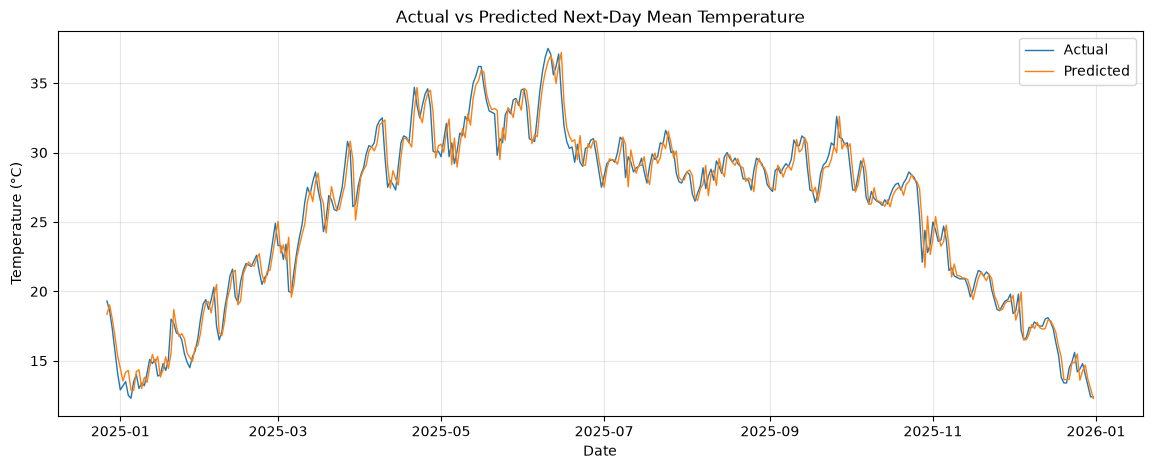

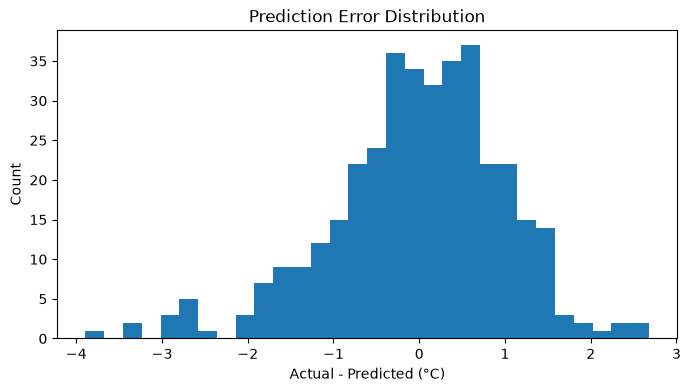

In [20]:
comparison = pd.DataFrame({
    "Date": data["target_date"].iloc[split_index:].values,
    "Actual temperature": y_test.values,
    "Predicted temperature": linear_pred
})

display(comparison.head(10).round(2))

plt.figure(figsize=(14, 5))
plt.plot(comparison["Date"], comparison["Actual temperature"], label="Actual", linewidth=1)
plt.plot(comparison["Date"], comparison["Predicted temperature"], label="Predicted", linewidth=1)
plt.title("Actual vs Predicted Next-Day Mean Temperature")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

errors = y_test.values - linear_pred
plt.figure(figsize=(8, 4))
plt.hist(errors, bins=30)
plt.title("Prediction Error Distribution")
plt.xlabel("Actual - Predicted (°C)")
plt.ylabel("Count")
plt.show()

,Model,MAE (°C),RMSE (°C),R²
1,Linear Regression,0.780,1.021,0.973
2,Random Forest,0.781,1.020,0.973
0,Mean baseline,5.503,6.267,-0.012


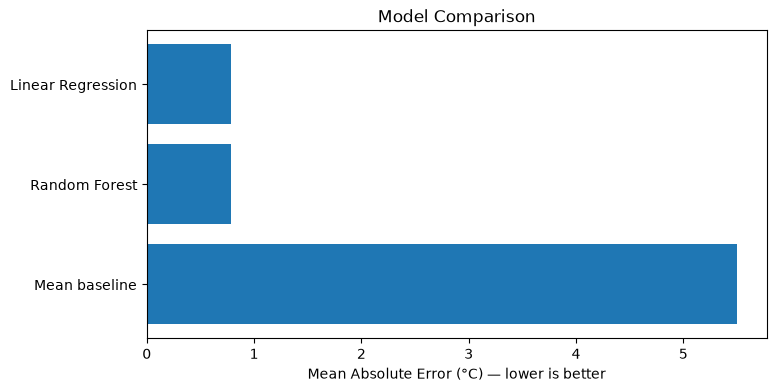

In [21]:
rf_model = RandomForestRegressor(
    n_estimators=150,
    random_state=42,
    min_samples_leaf=3,
    n_jobs=-1
)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

results.append(evaluate_model("Random Forest", y_test, rf_pred))
results_df = pd.DataFrame(results).sort_values("MAE (°C)")
display(results_df.round(3))

plt.figure(figsize=(8, 4))
plt.barh(results_df["Model"], results_df["MAE (°C)"])
plt.xlabel("Mean Absolute Error (°C) — lower is better")
plt.title("Model Comparison")
plt.gca().invert_yaxis()
plt.show()

In [22]:
print("Input features:")
print(X_train.columns.tolist())

print("\nTraining data shape:", X_train.shape)

print("\nSample input data:")
display(X_train.head())

print("\nTarget variable:")
print(y_train.name if hasattr(y_train, "name") else "Target")
display(y_train.head())

Input features:
['target_month', 'target_day_of_year', 'temp_lag_0', 'temp_lag_1', 'temp_lag_3', 'temp_lag_7', 'rolling_mean_7']

Training data shape: (1479, 7)

Sample input data:


,target_month,target_day_of_year,temp_lag_0,temp_lag_1,temp_lag_3,temp_lag_7,rolling_mean_7
0,12.0,344.0,19.0,19.4,18.6,17.6,18.557143
1,12.0,345.0,18.8,19.0,19.3,18.0,18.757143
2,12.0,346.0,19.3,18.8,19.4,18.4,18.871429
3,12.0,347.0,19.6,19.3,19.0,18.6,19.000000
4,12.0,348.0,19.7,19.6,18.8,18.6,19.142857



Target variable:
target_next_day


0    18.8
1    19.3
2    19.6
3    19.7
4    18.7
Name: target_next_day, dtype: float64

In [23]:
from pathlib import Path
import joblib

# Model save karne ke liye folder
Path("models").mkdir(exist_ok=True)

# Model aur features ko ek saath save karo
model_bundle = {
    "model": rf_model,
    "features": X_train.columns.tolist(),
    "target": "target_next_day"
}

joblib.dump(model_bundle, "models/weather_model.pkl")

print("Model successfully saved!")
print("Saved features:", model_bundle["features"])

Model successfully saved!
Saved features: ['target_month', 'target_day_of_year', 'temp_lag_0', 'temp_lag_1', 'temp_lag_3', 'temp_lag_7', 'rolling_mean_7']
